# 01 — Data Preparation

## Africa AI Readiness Investment Intelligence

### Objective

Prepare a reproducible, modelling-ready dataset of African urban centres for machine learning and sustainable infrastructure investment intelligence.

### Data preparation workflow

1. Load and validate the analytical dataset.
2. Review variables and select candidate modelling features.
3. Assess missing values and data quality.
4. Examine feature distributions and redundancy.
5. Apply appropriate transformations and scaling.
6. Save the modelling-ready dataset and preprocessing documentation.

**Principle:** Preserve the original analytical dataset and avoid unnecessary loss of observations or information.

# PART 1 — GHSL Data Preparation and Predictor Assessment

### Load our analytical dataset

In [1]:

from pathlib import Path
import pandas as pd
import numpy as np

# Project directories
PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

# Load the GHSL urban-centre analytical dataset
DATA_PATH = PROCESSED_DIR / "africa_ghsl_urban_centres_2172.csv"

df = pd.read_csv(DATA_PATH)

# Initial validation
print("Dataset shape:", df.shape)
print("Unique urban centres:", df["ID_UC_G0"].nunique())
print("Duplicate IDs:", df["ID_UC_G0"].duplicated().sum())
print("\nColumns:")
print(df.columns.tolist())

assert len(df) == 2172, "Unexpected number of urban centres"
assert df["ID_UC_G0"].is_unique, "Duplicate urban-centre identifiers detected"


Dataset shape: (2172, 24)
Unique urban centres: 2172
Duplicate IDs: 0

Columns:
['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_UCN_LIS_2025', 'GC_CNT_GAD_2025', 'GC_CNT_UNN_2025', 'GC_UCA_KM2_2025', 'GC_POP_TOT_2025', 'GC_DEV_WIG_2025', 'GC_DEV_USR_2025', 'GC_PLS_SCR_2025', 'GC_UCB_YOB_2025', 'GC_UCB_YOD_2025', 'GC_UCM_CAP', 'GH_POP_TOT_2025', 'IN_CIS_ENE_2020', 'IN_CIS_TRA_2020', 'IN_CIS_WAT_2020', 'IN_CIS_TEL_2020', 'IN_CIS_EDU_2020', 'IN_ROA_DEN_2024', 'SC_GDP_AVG_2020', 'SC_SEC_SYT_2020', 'CL_B01_CUR_2010', 'CL_REN_PVO_2020']


### Inspect the variables and missing values


#### Variable Inventory and Data Quality

Examine variable names, data types, missingness, and descriptive statistics before selecting modelling features.


In [2]:

# Build a variable inventory
variable_audit = pd.DataFrame({
    "Variable": df.columns,
    "Data_Type": df.dtypes.astype(str).values,
    "Non_Missing": df.notna().sum().values,
    "Missing": df.isna().sum().values,
    "Missing_Pct": (df.isna().mean() * 100).round(2).values,
    "Unique_Values": df.nunique(dropna=True).values
})

display(variable_audit)


,Variable,Data_Type,Non_Missing,Missing,Missing_Pct,Unique_Values
0,ID_UC_G0,int64,2172,0,0.00,2172
1,GC_UCN_MAI_2025,str,2172,0,0.00,2156
2,GC_UCN_LIS_2025,str,2042,130,5.99,2034
3,GC_CNT_GAD_2025,str,2172,0,0.00,56
4,GC_CNT_UNN_2025,str,2172,0,0.00,56
5,GC_UCA_KM2_2025,int64,2172,0,0.00,207
6,GC_POP_TOT_2025,float64,2172,0,0.00,2172
7,GC_DEV_WIG_2025,str,2165,7,0.32,3
8,GC_DEV_USR_2025,str,2172,0,0.00,2
9,GC_PLS_SCR_2025,str,2172,0,0.00,3


### Missing Data Assessment

The GHSL analytical dataset contains 2,172 African urban centres and 24 variables. Only three variables have missing values:

- **`GC_UCN_LIS_2025` (5.99%; n = 130):** Missing alternative urban-centre names. The primary name variable has complete coverage; therefore, no imputation is necessary.
- **`IN_ROA_DEN_2024` (0.05%; n = 1):** One missing road-density value. Retain the variable and assess appropriate imputation during preprocessing.
- **`CL_REN_PVO_2020` (0.05%; n = 1):** One missing solar photovoltaic potential value. Retain the variable and assess appropriate imputation during preprocessing.

**Conclusion:** Missingness is minimal and does not justify removing observations. All 2,172 urban centres will be retained at this stage, with missing numerical values addressed during preprocessing where necessary.


### Candidate Predictor Assessment

Review the distributions and completeness of candidate variables
before feature selection, transformation, and scaling.


In [3]:

# Initial candidate predictors from the GHSL dataset
candidate_features = [
    "GH_POP_TOT_2025",
    "IN_CIS_ENE_2020",
    "IN_CIS_TRA_2020",
    "IN_CIS_WAT_2020",
    "IN_CIS_TEL_2020",
    "IN_CIS_EDU_2020",
    "IN_ROA_DEN_2024",
    "SC_GDP_AVG_2020",
    "SC_SEC_SYT_2020",
    "CL_B01_CUR_2010",
    "CL_REN_PVO_2020"
]

# Inspect descriptive statistics
feature_summary = df[candidate_features].describe().T

feature_summary["Missing"] = (
    df[candidate_features].isna().sum()
)

feature_summary["Missing_Pct"] = (
    df[candidate_features].isna().mean() * 100
).round(2)

display(feature_summary.round(3))


,count,mean,std,min,25%,50%,75%,max,Missing,Missing_Pct
GH_POP_TOT_2025,2172.0,2.873367e+05,9.662781e+05,50007.746,67677.480,1.011437e+05,1.913242e+05,2.523032e+07,0,0.00
IN_CIS_ENE_2020,2172.0,1.200000e-02,1.800000e-02,0.000,0.000,5.000000e-03,1.800000e-02,1.330000e-01,0,0.00
IN_CIS_TRA_2020,2172.0,8.000000e-03,9.000000e-03,0.000,0.003,5.000000e-03,1.100000e-02,8.600000e-02,0,0.00
IN_CIS_WAT_2020,2172.0,0.000000e+00,6.000000e-03,0.000,0.000,0.000000e+00,0.000000e+00,1.460000e-01,0,0.00
IN_CIS_TEL_2020,2172.0,0.000000e+00,1.000000e-03,0.000,0.000,0.000000e+00,0.000000e+00,1.500000e-02,0,0.00
IN_CIS_EDU_2020,2172.0,2.000000e-03,5.000000e-03,0.000,0.000,0.000000e+00,2.000000e-03,8.400000e-02,0,0.00
IN_ROA_DEN_2024,2171.0,1.000000e-02,5.000000e-03,0.000,0.006,9.000000e-03,1.300000e-02,3.200000e-02,1,0.05
SC_GDP_AVG_2020,2172.0,2.170678e+07,2.060273e+07,575327.583,9078069.288,1.552954e+07,2.632614e+07,2.267162e+08,0,0.00
SC_SEC_SYT_2020,2172.0,6.077000e+00,2.900000e+00,0.330,3.353,6.286000e+00,8.446000e+00,1.378200e+01,0,0.00
CL_B01_CUR_2010,2172.0,2.382800e+01,3.877000e+00,11.181,21.154,2.476000e+01,2.673500e+01,3.087800e+01,0,0.00


### Check zero values

In [4]:

zero_audit = pd.DataFrame({
    "Variable": candidate_features,
    "Zero_Count": [(df[col] == 0).sum() for col in candidate_features],
    "Zero_Pct": [
        round((df[col] == 0).mean() * 100, 2)
        for col in candidate_features
    ]
})

display(zero_audit.sort_values("Zero_Pct", ascending=False))


,Variable,Zero_Count,Zero_Pct
3,IN_CIS_WAT_2020,1562,71.92
4,IN_CIS_TEL_2020,1174,54.05
5,IN_CIS_EDU_2020,879,40.47
1,IN_CIS_ENE_2020,734,33.79
2,IN_CIS_TRA_2020,1,0.05
0,GH_POP_TOT_2025,0,0.00
6,IN_ROA_DEN_2024,0,0.00
7,SC_GDP_AVG_2020,0,0.00
8,SC_SEC_SYT_2020,0,0.00
9,CL_B01_CUR_2010,0,0.00


### Zero-Value Assessment

An assessment of 11 candidate predictors across 2,172 African urban centres identified substantial zero-value prevalence in four Critical Infrastructures Spatial Indices (CISI): water (71.92%), telecommunications (54.05%), education (40.47%), and energy (33.79%). Transportation infrastructure recorded only one zero value (0.05%), while the remaining predictors recorded none.

These zeros are not treated as missing observations. Their interpretation requires reference to the underlying CISI methodology, as zero index values do not necessarily indicate the complete absence of infrastructure.

All 11 predictors are retained provisionally pending further examination of their distributions, measurement characteristics, correlations, and suitability for clustering.


### Nonzero Distribution Assessment — Critical Infrastructure Indices

The initial audit identified high proportions of zero values in four Critical Infrastructures Spatial Indices (CISI): water (71.92%), telecommunications (54.05%), education (40.47%), and energy (33.79%). This assessment examines the distribution and variability of their positive values to evaluate their suitability for clustering. Zero values are retained and not automatically interpreted as missing data or infrastructure absence; their meaning requires verification against the underlying CISI methodology. All four indicators remain provisional candidates pending further assessment.


In [5]:

# Examine nonzero values in the four zero-heavy CISI indicators

cisi_features = [
    "IN_CIS_WAT_2020",
    "IN_CIS_TEL_2020",
    "IN_CIS_EDU_2020",
    "IN_CIS_ENE_2020"
]

nonzero_results = []

for col in cisi_features:
    values = df[col].dropna()
    nonzero = values[values > 0]

    nonzero_results.append({
        "Variable": col,
        "Zero_Count": (values == 0).sum(),
        "Positive_Count": len(nonzero),
        "Positive_Unique": nonzero.nunique(),
        "Positive_Min": nonzero.min(),
        "Positive_Median": nonzero.median(),
        "Positive_Mean": nonzero.mean(),
        "Positive_Max": nonzero.max()
    })

nonzero_audit = pd.DataFrame(nonzero_results)

display(nonzero_audit.round(6))


,Variable,Zero_Count,Positive_Count,Positive_Unique,Positive_Min,Positive_Median,Positive_Mean,Positive_Max
0,IN_CIS_WAT_2020,1562,610,527,0.0,0.000038,0.001326,0.145777
1,IN_CIS_TEL_2020,1174,998,549,0.0,0.000438,0.000903,0.015339
2,IN_CIS_EDU_2020,879,1293,1215,0.0,0.001206,0.003269,0.083675
3,IN_CIS_ENE_2020,734,1438,1325,0.0,0.012606,0.018819,0.133374



**Interpretation:** Despite substantial zero prevalence, all four CISI indicators exhibit meaningful variation among positive observations, with 527–1,325 unique positive values. Their distributions are right-skewed, with means exceeding medians and relatively large maximum values. The displayed positive minima of 0.0 reflect rounding of very small positive values. These findings support provisional retention of the indicators, subject to verification of zero-value semantics, distributional assessment, and correlation analysis before clustering.



**CISI methodology verification:** The GHSL documentation identifies the energy, telecommunications, water and education infrastructure indicators as dimensionless spatial indices derived from Nirandjan et al. (2022), calculated using area-weighted mean subsector scores. However, the documentation does not explicitly establish whether zero values indicate absent infrastructure or limitations in the underlying mapped data. Consequently, zeros will be retained as recorded, without interpreting them as definitive evidence of infrastructure absence. The indicators remain provisional candidates pending verification against the original CISI methodology.


### Verification of CISI Zero Values

A review of Nirandjan et al. (2022), the original source of the Critical Infrastructure Spatial Index (CISI), confirms that zero values indicate **no mapped infrastructure intensity**, rather than verified absence of physical infrastructure. The indices are derived from OpenStreetMap (OSM) data extracted in January 2021, and their reliability is affected by incomplete and geographically uneven infrastructure mapping. Consequently, the high proportions of zeros observed in the water (71.92%), telecommunications (54.05%), education (40.47%), and energy (33.79%) indices may reflect both genuine infrastructure gaps and mapping limitations. **Decision:** Retain zero values as recorded, document their interpretation and uncertainty, and assess model sensitivity to excluding these indicators during subsequent analysis. All 2,172 urban centres remain in the analytical dataset.

**Reference:** Nirandjan, S., Koks, E. E., Ward, P. J., & Aerts, J. C. J. H. (2022). *A spatially-explicit harmonized global dataset of critical infrastructure*. Scientific Data, 9, 150. https://doi.org/10.1038/s41597-022-01218-4

### Examine correlations among the 11 candidate predictors

### Correlation and Redundancy Assessment

This analysis examines relationships among the 11 initial candidate predictors to identify potential redundancy and multicollinearity before feature selection. Spearman's rank correlation is used because the variables have different distributions, including highly skewed infrastructure indices and substantial zero values. Strong correlations will be investigated for conceptual overlap, but predictors will not be removed solely on the basis of a statistical threshold. Final decisions will consider each variable's relevance to sustainable infrastructure investment and AI readiness.

In [6]:

# Spearman correlation among candidate predictors
corr_matrix = df[candidate_features].corr(method="spearman")

display(corr_matrix.round(3))

# Identify strongly correlated predictor pairs
threshold = 0.80

strong_pairs = []

for i, col1 in enumerate(candidate_features):
    for col2 in candidate_features[i + 1:]:
        corr = corr_matrix.loc[col1, col2]

        if abs(corr) >= threshold:
            strong_pairs.append({
                "Variable_1": col1,
                "Variable_2": col2,
                "Spearman_rho": round(corr, 3)
            })

strong_corr_df = pd.DataFrame(
    strong_pairs,
    columns=["Variable_1", "Variable_2", "Spearman_rho"]
)

display(strong_corr_df)


,GH_POP_TOT_2025,IN_CIS_ENE_2020,IN_CIS_TRA_2020,IN_CIS_WAT_2020,IN_CIS_TEL_2020,IN_CIS_EDU_2020,IN_ROA_DEN_2024,SC_GDP_AVG_2020,SC_SEC_SYT_2020,CL_B01_CUR_2010,CL_REN_PVO_2020
GH_POP_TOT_2025,1.000,0.168,0.316,0.192,0.223,0.292,0.263,0.239,0.129,-0.006,0.008
IN_CIS_ENE_2020,0.168,1.000,0.691,0.264,0.243,0.399,0.394,0.488,0.417,-0.439,0.298
IN_CIS_TRA_2020,0.316,0.691,1.000,0.355,0.308,0.538,0.433,0.435,0.526,-0.303,0.119
IN_CIS_WAT_2020,0.192,0.264,0.355,1.000,0.406,0.403,0.302,0.152,0.142,-0.153,0.085
IN_CIS_TEL_2020,0.223,0.243,0.308,0.406,1.000,0.507,0.335,0.071,0.059,-0.121,0.064
IN_CIS_EDU_2020,0.292,0.399,0.538,0.403,0.507,1.000,0.420,0.152,0.250,-0.255,-0.014
IN_ROA_DEN_2024,0.263,0.394,0.433,0.302,0.335,0.420,1.000,0.266,0.069,-0.188,0.340
SC_GDP_AVG_2020,0.239,0.488,0.435,0.152,0.071,0.152,0.266,1.000,0.415,-0.236,0.239
SC_SEC_SYT_2020,0.129,0.417,0.526,0.142,0.059,0.250,0.069,0.415,1.000,-0.264,-0.175
CL_B01_CUR_2010,-0.006,-0.439,-0.303,-0.153,-0.121,-0.255,-0.188,-0.236,-0.264,1.000,-0.269


,Variable_1,Variable_2,Spearman_rho


### Correlation Assessment — Findings

Spearman's rank correlation analysis of the 11 initial candidate predictors identified no variable pairs with an absolute correlation coefficient ≥ 0.80, indicating no severe pairwise redundancy under the selected screening threshold. The strongest association was between energy and transportation infrastructure (ρ = 0.691). Several moderate correlations were observed among infrastructure, economic and education indicators. Consequently, all 11 predictors are provisionally retained for further assessment, subject to conceptual relevance, distributional characteristics and subsequent feature-selection diagnostics.

# PART 2 — External Infrastructure Data Integration and Validation

This section integrates the external digital infrastructure datasets developed during the exploratory phase with the GHSL urban-centre reference dataset. The objective is to assess the coverage, matching reliability, completeness and analytical suitability of ITU fibre proximity and PeeringDB infrastructure indicators across the 2,172 African urban centres. Integration decisions will be documented to ensure reproducibility and prevent unsupported assumptions about infrastructure availability.

### 2.1 ITU Fibre Proximity — Initial Data Audit

This section examines the ITU fibre proximity dataset prepared during Notebook 00 before integration with the GHSL urban-centre reference dataset. We assess its structure, urban-centre identifiers, coverage, missing values and potential duplicate records to establish whether it can be reliably joined to the 2,172 African urban centres without losing observations.

### Load and inspect the ITU fibre proximity dataset

In [7]:

# Load the ITU fibre proximity dataset
fibre_path = PROCESSED_DIR / "africa_itu_fibre_proximity.csv"

fibre_df = pd.read_csv(fibre_path)

print("Dataset shape:", fibre_df.shape)
print("\nColumns:")
print(fibre_df.columns.tolist())

print("\nFirst five records:")
display(fibre_df.head())

print("\nMissing values:")
display(fibre_df.isna().sum().to_frame("Missing_Count"))


Dataset shape: (2172, 4)

Columns:
['ID_UC_G0', 'X', 'Y', 'proximity']

First five records:


,ID_UC_G0,X,Y,proximity
0,38,-24.982595,16.884833,within 15km
1,39,-17.389242,14.744559,within 10km
2,40,-16.686812,13.407970,within 5km
3,41,-17.036314,20.948819,within 5km
4,43,-15.613077,11.867644,within 5km



Missing values:


,Missing_Count
ID_UC_G0,0
X,0
Y,0
proximity,0


### Validate identifiers and proximity categories

In [8]:

# Validate ITU fibre proximity records

print("Total records:", len(fibre_df))
print("Unique urban-centre IDs:", fibre_df["ID_UC_G0"].nunique())
print("Duplicate IDs:", fibre_df["ID_UC_G0"].duplicated().sum())

# Compare identifiers against the GHSL reference dataset
ghsl_ids = set(df["ID_UC_G0"])
fibre_ids = set(fibre_df["ID_UC_G0"])

print("\nGHSL IDs missing from fibre dataset:",
      len(ghsl_ids - fibre_ids))
print("Fibre IDs absent from GHSL dataset:",
      len(fibre_ids - ghsl_ids))

# Examine proximity categories and missing values
print("\nFibre proximity distribution:")
display(
    fibre_df["proximity"]
    .value_counts(dropna=False)
    .to_frame("Urban_Centres")
)


Total records: 2172
Unique urban-centre IDs: 2172
Duplicate IDs: 0

GHSL IDs missing from fibre dataset: 0
Fibre IDs absent from GHSL dataset: 0

Fibre proximity distribution:


,Urban_Centres
proximity,
within 5km,1005
within 50km,331
within 15km,143
within 10km,138
>100km,132
within 25km,127
within 20km,126
within 75km,119
within 100km,51


### 2.2 Integrating ITU Fibre Proximity with GHSL

The ITU fibre proximity dataset contains 2,172 unique urban-centre identifiers, with no duplicates or unmatched records relative to the GHSL reference dataset. The nine proximity categories provide a spatial measure of access to mapped terrestrial fibre infrastructure. A validated one-to-one left join is used to integrate these categories while preserving the complete GHSL urban-centre universe. Proximity categories are retained in their original form pending assessment of suitable numerical encoding.

In [9]:

# Preserve the GHSL reference dataset
integrated_df = df.copy()

# Join ITU fibre proximity using the urban-centre identifier
integrated_df = integrated_df.merge(
    fibre_df[["ID_UC_G0", "proximity"]],
    on="ID_UC_G0",
    how="left",
    validate="one_to_one"
)

# Verify integration
print("Integrated dataset shape:", integrated_df.shape)
print("Unique urban centres:", integrated_df["ID_UC_G0"].nunique())
print("Missing fibre proximity:", integrated_df["proximity"].isna().sum())

assert len(integrated_df) == 2172
assert integrated_df["ID_UC_G0"].is_unique
assert integrated_df["proximity"].notna().all()

print("\nITU fibre proximity integration successful.")


Integrated dataset shape: (2172, 25)
Unique urban centres: 2172
Missing fibre proximity: 0

ITU fibre proximity integration successful.


### ITU Fibre Proximity Integration — Findings

The ITU fibre proximity dataset was successfully integrated with the GHSL urban-centre reference dataset using a validated one-to-one join on `ID_UC_G0`. The resulting dataset contains 2,172 urban centres and 25 variables, with no duplicate identifiers, unmatched observations or missing fibre proximity values. The original proximity categories were retained for subsequent encoding and modelling assessment. Fibre proximity is interpreted as distance to mapped terrestrial fibre infrastructure rather than a direct measure of broadband availability or performance.

## Next: 2.3 — PeeringDB Infrastructure Data Audit

### 2.3 PeeringDB Infrastructure Data — Initial Audit

This section examines the PeeringDB infrastructure dataset prepared during Notebook 00 to assess its structure, geographic coverage, completeness and suitability for integration with the 2,172 African urban centres. Particular attention is given to identifying duplicate facilities, missing geographic information and potential multiple-facility assignments to individual urban centres. Integration will proceed only after the data structure and matching approach have been validated.

### Inspect the four PeeringDB file datasets

In [10]:
# Inspect PeeringDB datasets produced during Notebook 00

peering_files = {
    "Raw facilities": PROJECT_ROOT / "data/raw/peeringdb_africa_facilities.csv",
    "Georeferenced facilities": PROJECT_ROOT / "data/interim/peeringdb_africa_georeferenced.csv",
    "Facility assignment audit": PROJECT_ROOT / "data/processed/peeringdb_facility_assignment_audit.csv",
    "Urban centre reference": PROJECT_ROOT / "data/processed/peeringdb_urban_centre_reference.csv"
}

for name, path in peering_files.items():
    data = pd.read_csv(path)

    print(f"\n{'=' * 55}")
    print(name)
    print(f"Shape: {data.shape}")
    print(f"Columns: {data.columns.tolist()}")
    print("\nFirst three records:")
    display(data.head(3))
    print("\nMissing values:")
    display(data.isna().sum().to_frame("Missing_Count").T)


Raw facilities
Shape: (181, 39)
Columns: ['id', 'org_id', 'org_name', 'campus_id', 'name', 'aka', 'name_long', 'website', 'social_media', 'clli', 'rencode', 'npanxx', 'notes', 'net_count', 'ix_count', 'carrier_count', 'sales_email', 'sales_phone', 'tech_email', 'tech_phone', 'available_voltage_services', 'diverse_serving_substations', 'property', 'region_continent', 'status_dashboard', 'logo', 'created', 'updated', 'status', 'address1', 'address2', 'city', 'country', 'state', 'zipcode', 'floor', 'suite', 'latitude', 'longitude']

First three records:


,id,org_id,org_name,campus_id,name,aka,name_long,website,social_media,clli,...,address1,address2,city,country,state,zipcode,floor,suite,latitude,longitude
0,760,33533,Open Access Data Centres,NaN,OADC CPT3 - Cape Town,NaN,NaN,https://www.openaccessdc.net/,"[{'service': 'website', 'identifier': 'https:/...",NaN,...,"7th Floor, The Terraces",NaN,Cape Town,ZA,Western Cape,NaN,NaN,Floor 7,-33.918595,18.420575
1,850,6798,Teraco Data Environments Pty Ltd,NaN,"Teraco Johannesburg Campus, South Africa","Teraco JB1, Teraco JB3",NaN,http://www.teraco.co.za,"[{'service': 'website', 'identifier': 'http://...",NaN,...,5 Brewery Street,Isando,Johannesburg,ZA,GP,NaN,NaN,NaN,-26.137957,28.197517
2,993,3634,Digital Realty Lagos,NaN,Digital Realty Lagos (LOS1-2),NaN,NaN,https://www.digitalrealty.com,"[{'service': 'website', 'identifier': 'https:/...",NaN,...,8A Saka Tinubu Street Victoria Island,NaN,Lagos,NG,Lagos,101212,NaN,NaN,6.426645,3.417531



Missing values:


,id,org_id,org_name,campus_id,name,aka,name_long,website,social_media,clli,...,address1,address2,city,country,state,zipcode,floor,suite,latitude,longitude
Missing_Count,0,0,0,178,0,147,163,2,0,177,...,3,97,0,1,91,107,173,178,44,44



Georeferenced facilities
Shape: (137, 39)
Columns: ['id', 'org_id', 'org_name', 'campus_id', 'name', 'aka', 'name_long', 'website', 'social_media', 'clli', 'rencode', 'npanxx', 'notes', 'net_count', 'ix_count', 'carrier_count', 'sales_email', 'sales_phone', 'tech_email', 'tech_phone', 'available_voltage_services', 'diverse_serving_substations', 'property', 'region_continent', 'status_dashboard', 'logo', 'created', 'updated', 'status', 'address1', 'address2', 'city', 'country', 'state', 'zipcode', 'floor', 'suite', 'latitude', 'longitude']

First three records:


,id,org_id,org_name,campus_id,name,aka,name_long,website,social_media,clli,...,address1,address2,city,country,state,zipcode,floor,suite,latitude,longitude
0,760,33533,Open Access Data Centres,NaN,OADC CPT3 - Cape Town,NaN,NaN,https://www.openaccessdc.net/,"[{'service': 'website', 'identifier': 'https:/...",NaN,...,"7th Floor, The Terraces",NaN,Cape Town,ZA,Western Cape,NaN,NaN,Floor 7,-33.918595,18.420575
1,850,6798,Teraco Data Environments Pty Ltd,NaN,"Teraco Johannesburg Campus, South Africa","Teraco JB1, Teraco JB3",NaN,http://www.teraco.co.za,"[{'service': 'website', 'identifier': 'http://...",NaN,...,5 Brewery Street,Isando,Johannesburg,ZA,GP,NaN,NaN,NaN,-26.137957,28.197517
2,993,3634,Digital Realty Lagos,NaN,Digital Realty Lagos (LOS1-2),NaN,NaN,https://www.digitalrealty.com,"[{'service': 'website', 'identifier': 'https:/...",NaN,...,8A Saka Tinubu Street Victoria Island,NaN,Lagos,NG,Lagos,101212,NaN,NaN,6.426645,3.417531


... (6 outputs left out)


Urban centre reference
Shape: (2172, 5)
Columns: ['ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'peeringdb_facility_count', 'peeringdb_observed_presence']

First three records:


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,peeringdb_facility_count,peeringdb_observed_presence
0,38,Mindelo,Cabo Verde,0,0
1,39,Dakar,Senegal,2,1
2,40,Serrekunda,Gambia,0,0



Missing values:


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,peeringdb_facility_count,peeringdb_observed_presence
Missing_Count,0,9,0,0,0


### Validate facility assignments

In [11]:
# Inspect PeeringDB facility assignment audit

assignment_df = pd.read_csv(
    PROJECT_ROOT / "data/processed/peeringdb_facility_assignment_audit.csv"
)

print("Dataset shape:", assignment_df.shape)
print("\nColumns:")
print(assignment_df.columns.tolist())

print("\nFirst 10 records:")
display(assignment_df.head(10))

print("\nMissing values:")
display(assignment_df.isna().sum().to_frame("Missing_Count"))

Dataset shape: (137, 50)

Columns:
['id', 'org_id', 'org_name', 'campus_id', 'name', 'aka', 'name_long', 'website', 'social_media', 'clli', 'rencode', 'npanxx', 'notes', 'net_count', 'ix_count', 'carrier_count', 'sales_email', 'sales_phone', 'tech_email', 'tech_phone', 'available_voltage_services', 'diverse_serving_substations', 'property', 'region_continent', 'status_dashboard', 'logo', 'created', 'updated', 'status', 'address1', 'address2', 'city', 'country', 'state', 'zipcode', 'floor', 'suite', 'latitude', 'longitude', 'index_right', 'ID_UC_G0', 'GC_UCN_MAI_2025', 'GC_CNT_GAD_2025', 'assignment_method', 'assignment_status', 'assignment_distance_km', 'review_uc_id', 'review_distance_km', 'review_method', 'review_status']

First 10 records:


,id,org_id,org_name,campus_id,name,aka,name_long,website,social_media,clli,...,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,assignment_method,assignment_status,assignment_distance_km,review_uc_id,review_distance_km,review_method,review_status
0,760,33533,Open Access Data Centres,NaN,OADC CPT3 - Cape Town,NaN,NaN,https://www.openaccessdc.net/,"[{'service': 'website', 'identifier': 'https:/...",NaN,...,431.0,Cape Town,South Africa,point_in_polygon,direct_match,0.0,NaN,NaN,NaN,NaN
1,850,6798,Teraco Data Environments Pty Ltd,NaN,"Teraco Johannesburg Campus, South Africa","Teraco JB1, Teraco JB3",NaN,http://www.teraco.co.za,"[{'service': 'website', 'identifier': 'http://...",NaN,...,3512.0,Johannesburg,South Africa,point_in_polygon,direct_match,0.0,NaN,NaN,NaN,NaN
2,993,3634,Digital Realty Lagos,NaN,Digital Realty Lagos (LOS1-2),NaN,NaN,https://www.digitalrealty.com,"[{'service': 'website', 'identifier': 'https:/...",NaN,...,1289.0,Lagos,Nigeria,point_in_polygon,direct_match,0.0,NaN,NaN,NaN,NaN
3,1225,6798,Teraco Data Environments Pty Ltd,NaN,"Teraco CT1 Cape Town, South Africa",Teraco CT1,NaN,http://www.teraco.co.za/,"[{'service': 'website', 'identifier': 'http://...",NaN,...,431.0,Cape Town,South Africa,point_in_polygon,direct_match,0.0,NaN,NaN,NaN,NaN
4,1275,6616,Angola Cables,NaN,AngoNAP Luanda,NaN,NaN,https://www.angolacables.co.ao/,"[{'service': 'website', 'identifier': 'https:/...",NaN,...,1082.0,Luanda,Angola,point_in_polygon,direct_match,0.0,NaN,NaN,NaN,NaN
5,1289,6798,Teraco Data Environments Pty Ltd,NaN,"Teraco DB1 Durban, South Africa",NaN,NaN,http://www.teraco.co.za,"[{'service': 'website', 'identifier': 'http://...",NaN,...,4787.0,Durban,South Africa,point_in_polygon,direct_match,0.0,NaN,NaN,NaN,NaN
6,1301,6803,Bunker One Management,NaN,Bunker One,NaN,NaN,http://www.bunkerone.co.za/,"[{'service': 'website', 'identifier': 'http://...",NaN,...,3512.0,Johannesburg,South Africa,point_in_polygon,direct_match,0.0,NaN,NaN,NaN,NaN
7,1578,8102,"University of Malawi, College of Medicine",NaN,"University of Malawi, College of Medicine",NaN,NaN,http://www.medcol.mw/,"[{'service': 'website', 'identifier': 'http://...",NaN,...,873.0,Blantyre,Malawi,point_in_polygon,direct_match,0.0,NaN,NaN,NaN,NaN
8,1888,9810,ATLAX,NaN,ATLAX,NaN,NaN,http://www.atlax.com,"[{'service': 'website', 'identifier': 'http://...",NaN,...,1399.0,Tunis,Tunisia,point_in_polygon,direct_match,0.0,NaN,NaN,NaN,NaN
9,1964,20800,Africa Data Centres,NaN,"Africa Data Centres, Nairobi NBO1, Kenya",NaN,NaN,http://www.eastafricadatacentre.com/,"[{'service': 'website', 'identifier': 'http://...",NaN,...,1717.0,Nairobi,Kenya,point_in_polygon,direct_match,0.0,NaN,NaN,NaN,NaN



Missing values:


,Missing_Count
id,0
org_id,0
org_name,0
campus_id,134
name,0
aka,106
name_long,122
website,0
social_media,0
clli,135


### Examine assignment outcomes

In [12]:
# Summarise PeeringDB geographic assignment outcomes

print("Assignment methods:")
display(assignment_df["assignment_method"].value_counts(dropna=False))

print("\nAssignment statuses:")
display(assignment_df["assignment_status"].value_counts(dropna=False))

print("\nReview statuses:")
display(assignment_df["review_status"].value_counts(dropna=False))

print("\nAssigned GHSL urban centres:")
print(assignment_df["ID_UC_G0"].nunique())

print("\nFacilities without GHSL assignment:")
unassigned = assignment_df[assignment_df["ID_UC_G0"].isna()]

display(
    unassigned[
        ["id", "name", "city", "country",
         "assignment_method", "assignment_status",
         "assignment_distance_km"]
    ].head(30)
)

Assignment methods:


assignment_method
point_in_polygon      113
proximity              17
pending_review          5
proximity_reviewed      2
Name: count, dtype: int64


Assignment statuses:


assignment_status
direct_match    113
provisional      19
unresolved        5
Name: count, dtype: int64


Review statuses:


review_status
NaN            113
provisional     19
unresolved       5
Name: count, dtype: int64


Assigned GHSL urban centres:
52

Facilities without GHSL assignment:


,id,name,city,country,assignment_method,assignment_status,assignment_distance_km
11,2031,SEACOM Mtunzini CLS,Mtunzini,ZA,pending_review,unresolved,NaN
20,3417,Beonline 24/7,Groot Drakenstein,ZA,pending_review,unresolved,NaN
63,9041,SIPOPO DATACENTER,Malabo,GQ,pending_review,unresolved,NaN
116,14016,Dolphin Coast Wireless & Fiber Solutions,Ballito,ZA,pending_review,unresolved,NaN
117,14075,Mauritius Telecom RBDC,Rose Belle,MU,pending_review,unresolved,NaN


### PeeringDB Facility Assignment — Findings

Of the 137 georeferenced PeeringDB facilities, 113 (82.5%) were directly matched to 52 unique GHSL urban centres, while 19 (13.9%) received provisional assignments and five (3.6%) remained unresolved. Only direct matches will be retained for the initial high-confidence facility aggregation, with provisional and unresolved records excluded pending further review. Multiple facilities within the same urban centre will be aggregated using unique facility counts before integration with the 2,172-city dataset. Since PeeringDB does not provide a complete census of digital infrastructure, zero recorded facilities will be interpreted as absence of observed PeeringDB facilities rather than verified absence of infrastructure.

### 2.4 PeeringDB — High-Confidence Facility Aggregation

In [13]:
# Retain direct geographic matches only
direct_facilities = assignment_df[
    (assignment_df["assignment_status"] == "direct_match")
    & assignment_df["ID_UC_G0"].notna()
].copy()

# Aggregate facilities by GHSL urban-centre identifier
facility_counts = (
    direct_facilities
    .groupby("ID_UC_G0")
    .agg(
        peeringdb_facility_count=("id", "nunique")
    )
    .reset_index()
)

# Ensure identifiers match the GHSL dataset
facility_counts["ID_UC_G0"] = (
    facility_counts["ID_UC_G0"].astype(df["ID_UC_G0"].dtype)
)

print("Direct-match facility records:", len(direct_facilities))
print("Unique urban centres:", len(facility_counts))
print("Total unique facilities:", facility_counts["peeringdb_facility_count"].sum())

print("\nFacility counts by urban centre:")
display(
    facility_counts.sort_values(
        "peeringdb_facility_count", ascending=False
    ).head(15)
)

Direct-match facility records: 113
Unique urban centres: 48
Total unique facilities: 113

Facility counts by urban centre:


,ID_UC_G0,peeringdb_facility_count
17,1289,10
16,1082,7
37,3512,7
23,1717,6
9,431,5
35,3175,5
38,3570,5
5,299,4
40,3986,4
20,1487,3


### Verify the 48 versus 52 difference

In [14]:

# Compare all assigned centres with direct-match centres
all_assigned = assignment_df["ID_UC_G0"].dropna().nunique()

direct_assigned = assignment_df.loc[
    assignment_df["assignment_status"] == "direct_match",
    "ID_UC_G0"
].dropna().nunique()

print("All assigned urban centres:", all_assigned)
print("Direct-match urban centres:", direct_assigned)
print("Centres represented only by non-direct assignments:",
      all_assigned - direct_assigned)


All assigned urban centres: 52
Direct-match urban centres: 48
Centres represented only by non-direct assignments: 4


**PeeringDB Geographic Assignment Verification — Findings**

The discrepancy between 52 assigned urban centres and 48 directly matched urban centres was resolved through an identifier-level verification. Of the 52 urban centres with assigned PeeringDB facilities, 48 have at least one direct geographic match, while four are represented exclusively by non-direct assignments. The high-confidence dataset therefore retains 113 directly matched facilities across 48 urban centres. Provisional and unresolved assignments remain excluded from the initial aggregation, preserving geographic reliability. A zero facility count will indicate no directly matched PeeringDB facility observed, rather than confirmed absence of digital infrastructure.

### 2.5 — PeeringDB Integration with GHSL Urban Centres:

In [15]:

# Integrate high-confidence PeeringDB facility counts
integrated_df = integrated_df.merge(
    facility_counts,
    on="ID_UC_G0",
    how="left",
    validate="one_to_one"
)

# No observed direct-match facility is coded as zero
integrated_df["peeringdb_facility_count"] = (
    integrated_df["peeringdb_facility_count"]
    .fillna(0)
    .astype(int)
)

# Verify integration
print("Dataset shape:", integrated_df.shape)
print("Unique urban centres:", integrated_df["ID_UC_G0"].nunique())
print("Centres with observed facilities:",
      (integrated_df["peeringdb_facility_count"] > 0).sum())
print("Total directly matched facilities:",
      integrated_df["peeringdb_facility_count"].sum())

assert len(integrated_df) == 2172
assert integrated_df["ID_UC_G0"].is_unique
assert integrated_df["peeringdb_facility_count"].sum() == 113


Dataset shape: (2172, 26)
Unique urban centres: 2172
Centres with observed facilities: 48
Total directly matched facilities: 113


**PeeringDB Integration — Findings**

The high-confidence PeeringDB facility dataset was successfully integrated with the GHSL urban-centre dataset using a validated one-to-one join on `ID_UC_G0`. The resulting analytical dataset contains 2,172 unique African urban centres and 26 variables, with no loss of observations. A total of 113 directly matched facilities were aggregated across 48 urban centres (2.21%). Urban centres without directly matched facilities were assigned a count of zero, indicating no observed facility in the selected PeeringDB records rather than confirmed infrastructure absence. Given its sparse coverage, the indicator is retained for further assessment, with its suitability for clustering to be determined during feature selection.


# PART 3 — Final Data Quality Assessment and Preparation for Clustering

This section assesses the completeness, structural integrity and analytical suitability of the integrated GHSL, ITU fibre proximity and PeeringDB dataset. We will examine missing values, duplicate records, variable types and distributions before encoding categorical indicators, selecting clustering features and applying appropriate transformations. The objective is to preserve all 2,172 African urban centres while preparing a transparent and reproducible modelling dataset.



## 3.1 Final Integrated Dataset Validation


In [16]:

# Final structural and missing-value audit

print("Dataset shape:", integrated_df.shape)
print("Unique urban centres:", integrated_df["ID_UC_G0"].nunique())
print("Duplicate IDs:", integrated_df["ID_UC_G0"].duplicated().sum())

# Examine variable types and missing values
final_audit = pd.DataFrame({
    "Variable": integrated_df.columns,
    "Data_Type": integrated_df.dtypes.astype(str).values,
    "Missing": integrated_df.isna().sum().values,
    "Missing_Pct": (
        integrated_df.isna().mean().values * 100
    ).round(2),
    "Unique_Values": integrated_df.nunique(dropna=True).values
})

display(
    final_audit.sort_values(
        "Missing",
        ascending=False
    ).reset_index(drop=True)
)

# Confirm structural integrity
assert len(integrated_df) == 2172
assert integrated_df["ID_UC_G0"].is_unique

print("\nStructural validation passed.")


Dataset shape: (2172, 26)
Unique urban centres: 2172
Duplicate IDs: 0


,Variable,Data_Type,Missing,Missing_Pct,Unique_Values
0,GC_UCN_LIS_2025,str,130,5.99,2034
1,GC_DEV_WIG_2025,str,7,0.32,3
2,IN_ROA_DEN_2024,float64,1,0.05,2170
3,CL_REN_PVO_2020,float64,1,0.05,1204
4,GC_UCN_MAI_2025,str,0,0.00,2156
5,ID_UC_G0,int64,0,0.00,2172
6,GC_UCA_KM2_2025,int64,0,0.00,207
7,GC_POP_TOT_2025,float64,0,0.00,2172
8,GC_CNT_UNN_2025,str,0,0.00,56
9,GC_CNT_GAD_2025,str,0,0.00,56



Structural validation passed.


**Final Integrated Dataset Validation — Findings**

The integrated GHSL, ITU fibre proximity and PeeringDB dataset contains 2,172 unique African urban centres and 26 variables, with no duplicate identifiers. Missing values occur in only four variables: alternative urban-centre names (130; 5.99%), a GHSL descriptive classification (7; 0.32%), road network density (1; 0.05%) and solar photovoltaic potential (1; 0.05%). All remaining variables, including the integrated fibre proximity and PeeringDB facility indicators, have complete coverage. No observations will be removed at this stage. Missing numerical predictor values will be addressed during modelling preprocessing, while descriptive missing values will be retained without imputation.


## 3.2 Fibre Proximity Encoding Assessment

The ITU fibre proximity indicator is an ordered categorical variable representing proximity to mapped terrestrial fibre infrastructure. Before converting it to a numerical representation for clustering, we examine the category distribution and determine an appropriate encoding strategy. The transformation must preserve the interpretation of proximity without implying unsupported precision in the underlying distance estimates.


In [17]:

# Inspect fibre proximity categories and frequencies

fibre_distribution = (
    integrated_df["proximity"]
    .value_counts(dropna=False)
    .rename_axis("Fibre_Proximity")
    .reset_index(name="Urban_Centres")
)

fibre_distribution["Percentage"] = (
    fibre_distribution["Urban_Centres"]
    / len(integrated_df) * 100
).round(2)

display(fibre_distribution)

print("Total urban centres:",
      fibre_distribution["Urban_Centres"].sum())

print("Unique proximity categories:",
      integrated_df["proximity"].nunique())


,Fibre_Proximity,Urban_Centres,Percentage
0,within 5km,1005,46.27
1,within 50km,331,15.24
2,within 15km,143,6.58
3,within 10km,138,6.35
4,>100km,132,6.08
5,within 25km,127,5.85
6,within 20km,126,5.80
7,within 75km,119,5.48
8,within 100km,51,2.35


Total urban centres: 2172
Unique proximity categories: 9


**Fibre Proximity Assessment — Findings**

All 2,172 urban centres have valid ITU fibre proximity classifications across nine ordered distance categories. Approximately 46.27% are within 5 km of mapped terrestrial fibre infrastructure, while 6.08% are classified beyond 100 km. An ordinal distance-band representation is adopted for initial modelling preparation, retaining the original categories for reference. The open-ended category (>100 km) is provisionally encoded as 125 km and will be subject to sensitivity assessment. Encoded values represent distance-band approximations rather than measured distances, and fibre proximity is not interpreted as evidence of broadband performance or service availability.

## Create the encoded variable


### Fibre Proximity Encoding — Methodological Note

The nine ITU fibre proximity categories were converted into numerical distance-band values (5–100 km) to support clustering. The open-ended category (>100 km) was provisionally assigned 125 km for modelling purposes. These values represent approximate distance thresholds rather than measured distances. The original categories are retained for reference, and the influence of the provisional 125 km value will be assessed through sensitivity analysis before finalizing the clustering model.


In [18]:

# Encode ITU fibre proximity categories

fibre_mapping = {
    "within 5km": 5,
    "within 10km": 10,
    "within 15km": 15,
    "within 20km": 20,
    "within 25km": 25,
    "within 50km": 50,
    "within 75km": 75,
    "within 100km": 100,
    ">100km": 125
}

integrated_df["fibre_distance_band_km"] = (
    integrated_df["proximity"].map(fibre_mapping)
)

# Validate encoding
assert integrated_df["fibre_distance_band_km"].notna().all()
assert len(integrated_df) == 2172

print("Dataset shape:", integrated_df.shape)

display(
    integrated_df.groupby(
        ["proximity", "fibre_distance_band_km"]
    ).size().reset_index(name="Urban_Centres")
    .sort_values("fibre_distance_band_km")
)


Dataset shape: (2172, 27)


,proximity,fibre_distance_band_km,Urban_Centres
7,within 5km,5,1005
2,within 10km,10,138
3,within 15km,15,143
4,within 20km,20,126
5,within 25km,25,127
6,within 50km,50,331
8,within 75km,75,119
1,within 100km,100,51
0,>100km,125,132



## 3.3 Missing Numerical Values — Case Assessment

Two candidate predictors contain one missing observation each: road network density and solar photovoltaic potential. The affected urban centres will be identified before selecting an appropriate imputation strategy, with the objective of preserving all 2,172 observations.


In [19]:

# Identify urban centres with missing numerical predictors

missing_cases = integrated_df.loc[
    integrated_df[
        ["IN_ROA_DEN_2024", "CL_REN_PVO_2020"]
    ].isna().any(axis=1),
    [
        "ID_UC_G0",
        "GC_UCN_MAI_2025",
        "GC_CNT_GAD_2025",
        "IN_ROA_DEN_2024",
        "CL_REN_PVO_2020"
    ]
]

display(missing_cases)

print("Affected urban centres:", len(missing_cases))


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,IN_ROA_DEN_2024,CL_REN_PVO_2020
0,38,Mindelo,Cabo Verde,0.013276,NaN
754,2899,Muala,Mozambique,NaN,4.578


Affected urban centres: 2



### Missing Numerical Values — Findings

Two missing observations were identified: solar PV potential for Mindelo (Cabo Verde) and road network density for Muala (Mozambique), representing 0.09% of the 2,172 urban centres. Country-level median imputation was selected, with a continental median fallback where necessary, to preserve the complete analytical universe. Original values remain unchanged in the source dataset, and imputation decisions are documented for reproducibility.



### 3.3 Missing Numerical Values — Imputation Strategy

Two urban centres (0.09% of 2,172) have missing numerical values: Mindelo, Cabo Verde (solar PV potential), and Muala, Mozambique (road network density). To preserve the complete analytical dataset, missing values will be imputed using the median of the corresponding variable within each country, with the African continental median as a fallback where country-level estimates are unavailable. This geographically informed approach is preferred over deleting observations or applying a uniform continental estimate. The original dataset will remain unchanged, and all imputed values and methods will be recorded for reproducibility. Feature scaling will be addressed separately during clustering preparation.


In [20]:

# Preserve the original values before imputation
imputed_df = integrated_df.copy()

imputation_log = []

for col in ["IN_ROA_DEN_2024", "CL_REN_PVO_2020"]:
    missing_mask = imputed_df[col].isna()

    for idx in imputed_df.index[missing_mask]:
        country = imputed_df.loc[idx, "GC_CNT_GAD_2025"]

        country_median = imputed_df.loc[
            imputed_df["GC_CNT_GAD_2025"] == country, col
        ].median()

        # Use continental median only if country data are unavailable
        if pd.isna(country_median):
            replacement = imputed_df[col].median()
            method = "Africa median"
        else:
            replacement = country_median
            method = "Country median"

        imputed_df.loc[idx, col] = replacement

        imputation_log.append({
            "Urban_Centre": imputed_df.loc[idx, "GC_UCN_MAI_2025"],
            "Country": country,
            "Variable": col,
            "Imputed_Value": replacement,
            "Method": method
        })

display(pd.DataFrame(imputation_log))

print("Remaining missing numerical values:",
      imputed_df[["IN_ROA_DEN_2024", "CL_REN_PVO_2020"]]
      .isna().sum().sum())

print("Dataset shape:", imputed_df.shape)


,Urban_Centre,Country,Variable,Imputed_Value,Method
0,Muala,Mozambique,IN_ROA_DEN_2024,0.008759,Country median
1,Mindelo,Cabo Verde,CL_REN_PVO_2020,4.327000,Country median


Remaining missing numerical values: 0
Dataset shape: (2172, 27)



### Imputation — Verification Findings

Country-level median imputation was successfully applied to the two missing numerical observations: road density for Muala, Mozambique (0.008759), and solar PV potential for Mindelo, Cabo Verde (4.327000). No continental fallback was required. Both variables now have complete coverage, and the analytical dataset retains all 2,172 urban centres and 27 columns. The original dataset remains unchanged, and the imputation methods and replacement values have been documented.



### 3.4 Final Candidate Feature Selection for Clustering

This section evaluates the integrated variables for their suitability in identifying sustainable AI infrastructure readiness profiles across 2,172 African urban centres. Feature selection considers conceptual relevance, data completeness, measurement limitations, redundancy and suitability for distance-based clustering. Geographic identifiers and descriptive attributes will be retained for interpretation but excluded from clustering. The sparse PeeringDB facility count will initially be reserved for external cluster profiling. The final feature set remains provisional until distributional and scaling assessments are completed.


### Create and validate the feature matrix

In [21]:

# Section 3.4 — Initial clustering feature selection

clustering_features = [
    "GH_POP_TOT_2025",
    "SC_GDP_AVG_2020",
    "IN_CIS_ENE_2020",
    "IN_CIS_TEL_2020",
    "fibre_distance_band_km",
    "IN_CIS_TRA_2020",
    "IN_ROA_DEN_2024",
    "SC_SEC_SYT_2020",
    "IN_CIS_EDU_2020",
    "IN_CIS_WAT_2020",
    "CL_REN_PVO_2020",
    "CL_B01_CUR_2010"
]

# Verify that all selected features exist
missing_columns = [
    col for col in clustering_features
    if col not in imputed_df.columns
]

assert not missing_columns, (
    f"Missing feature columns: {missing_columns}"
)

# Create the unscaled candidate feature matrix
X_candidate = imputed_df[clustering_features].copy()

# Check data types, missing values and variation
feature_audit = pd.DataFrame({
    "Data_Type": X_candidate.dtypes.astype(str),
    "Missing": X_candidate.isna().sum(),
    "Unique_Values": X_candidate.nunique()
})

display(feature_audit)

print("Candidate feature matrix:", X_candidate.shape)
print("Total missing values:", X_candidate.isna().sum().sum())

assert X_candidate.shape == (2172, 12)
assert X_candidate.isna().sum().sum() == 0
assert all(X_candidate.nunique() > 1)

print("Initial feature selection validation passed.")


,Data_Type,Missing,Unique_Values
GH_POP_TOT_2025,float64,0,2172
SC_GDP_AVG_2020,float64,0,2172
IN_CIS_ENE_2020,float64,0,1326
IN_CIS_TEL_2020,float64,0,550
fibre_distance_band_km,int64,0,9
IN_CIS_TRA_2020,float64,0,2026
IN_ROA_DEN_2024,float64,0,2170
SC_SEC_SYT_2020,float64,0,567
IN_CIS_EDU_2020,float64,0,1216
IN_CIS_WAT_2020,float64,0,528


Candidate feature matrix: (2172, 12)
Total missing values: 0
Initial feature selection validation passed.



### Initial Feature Selection — Findings

Twelve candidate clustering features were selected across demographic, economic, infrastructure, human-capital and environmental dimensions. The resulting feature matrix contains 2,172 urban centres and 12 numerical variables, with no missing values or constant features. All candidates are provisionally retained pending distributional assessment, transformation and scaling. The PeeringDB facility count is excluded from the initial clustering matrix and reserved for subsequent cluster profiling.


### Examine skewness and extreme values

In [22]:

# Section 3.4 — Distribution and skewness assessment

distribution_audit = pd.DataFrame({
    "Min": X_candidate.min(),
    "Median": X_candidate.median(),
    "Mean": X_candidate.mean(),
    "Max": X_candidate.max(),
    "Skewness": X_candidate.skew(),
    "P95": X_candidate.quantile(0.95),
    "P99": X_candidate.quantile(0.99)
})

display(distribution_audit.round(4))


,Min,Median,Mean,Max,Skewness,P95,P99
GH_POP_TOT_2025,50007.7464,1.011437e+05,2.873367e+05,2.523032e+07,13.1127,8.065625e+05,4.279323e+06
SC_GDP_AVG_2020,575327.5833,1.552954e+07,2.170678e+07,2.267162e+08,3.0003,6.097367e+07,1.038703e+08
IN_CIS_ENE_2020,0.0000,5.400000e-03,1.250000e-02,1.334000e-01,1.9530,4.970000e-02,7.160000e-02
IN_CIS_TEL_2020,0.0000,0.000000e+00,4.000000e-04,1.530000e-02,5.4542,2.000000e-03,5.100000e-03
fibre_distance_band_km,5.0000,1.000000e+01,2.823200e+01,1.250000e+02,1.6162,1.250000e+02,1.250000e+02
IN_CIS_TRA_2020,0.0000,5.300000e-03,8.500000e-03,8.610000e-02,3.0174,2.570000e-02,4.250000e-02
IN_ROA_DEN_2024,0.0000,9.300000e-03,9.600000e-03,3.190000e-02,0.4201,1.780000e-02,2.140000e-02
SC_SEC_SYT_2020,0.3300,6.286000e+00,6.077300e+00,1.378200e+01,0.0844,1.062000e+01,1.264500e+01
IN_CIS_EDU_2020,0.0000,1.000000e-04,1.900000e-03,8.370000e-02,6.7646,9.100000e-03,2.370000e-02
IN_CIS_WAT_2020,0.0000,0.000000e+00,4.000000e-04,1.458000e-01,22.2600,3.000000e-04,2.300000e-03


# Inspect the entire integrated dataset

In [23]:

# Inspect the complete integrated dataset

print("Dataset shape:", imputed_df.shape)

print("\nAll columns and data types:")
display(
    pd.DataFrame({
        "Column": imputed_df.columns,
        "Data_Type": imputed_df.dtypes.astype(str).values,
        "Missing": imputed_df.isna().sum().values
    })
)

print("\nFirst 10 urban centres — all 27 columns:")
with pd.option_context(
    "display.max_columns", None,
    "display.width", 200,
    "display.max_colwidth", 40
):
    display(imputed_df.head(10))


Dataset shape: (2172, 27)

All columns and data types:


,Column,Data_Type,Missing
0,ID_UC_G0,int64,0
1,GC_UCN_MAI_2025,str,0
2,GC_UCN_LIS_2025,str,130
3,GC_CNT_GAD_2025,str,0
4,GC_CNT_UNN_2025,str,0
5,GC_UCA_KM2_2025,int64,0
6,GC_POP_TOT_2025,float64,0
7,GC_DEV_WIG_2025,str,7
8,GC_DEV_USR_2025,str,0
9,GC_PLS_SCR_2025,str,0



First 10 urban centres — all 27 columns:


,ID_UC_G0,GC_UCN_MAI_2025,GC_UCN_LIS_2025,GC_CNT_GAD_2025,GC_CNT_UNN_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025,GC_DEV_USR_2025,GC_PLS_SCR_2025,GC_UCB_YOB_2025,GC_UCB_YOD_2025,GC_UCM_CAP,GH_POP_TOT_2025,IN_CIS_ENE_2020,IN_CIS_TRA_2020,IN_CIS_WAT_2020,IN_CIS_TEL_2020,IN_CIS_EDU_2020,IN_ROA_DEN_2024,SC_GDP_AVG_2020,SC_SEC_SYT_2020,CL_B01_CUR_2010,CL_REN_PVO_2020,proximity,peeringdb_facility_count,fibre_distance_band_km
0,38,Mindelo,Mindelo,Cabo Verde,Cabo Verde,18,8.827388e+04,Lower Middle,Sub-Saharan Africa,High,2000,2030,0,8.827388e+04,2.620000e-08,0.002402,6.260000e-09,2.460000e-07,0.000719,0.013276,2.466210e+07,6.713000,23.108,4.327,within 15km,0,15
1,39,Dakar,Dakar; GuÃ©diawaye; Pikine; Rufisque,Senegal,Senegal,277,3.970202e+06,Lower Middle,Sub-Saharan Africa,High,1975,2030,1,3.970202e+06,2.131755e-02,0.038976,1.617000e-04,1.385724e-03,0.020982,0.020983,6.282993e+07,5.047000,24.496,4.747,within 10km,2,10
2,40,Serrekunda,Serrekunda,Gambia,Gambia,181,1.313465e+06,Low income,Sub-Saharan Africa,High,1975,2030,0,1.313465e+06,4.863860e-04,0.012696,5.970000e-05,1.402762e-03,0.004661,0.014302,1.359119e+07,5.764927,25.180,4.672,within 5km,0,5
3,41,Nouadhibou,Nouadhibou,Mauritania,Mauritania,38,1.774690e+05,Lower Middle,Sub-Saharan Africa,High,1995,2030,0,1.774690e+05,1.800000e-05,0.006597,3.690000e-06,5.439420e-04,0.000048,0.011540,2.835348e+07,9.137000,20.147,5.101,within 5km,0,5
4,43,Bissau,Bissau,Guinea-Bissau,Guinea-Bissau,83,6.744443e+05,Low income,Sub-Saharan Africa,High,1975,2030,1,6.744443e+05,0.000000e+00,0.006249,0.000000e+00,2.830000e-06,0.000695,0.008329,1.800221e+07,6.934985,26.630,4.519,within 5km,0,5
5,46,Kamsar,Kamsar,Guinea,Guinea,31,1.279576e+05,Lower Middle,Sub-Saharan Africa,High,1990,2030,0,1.279576e+05,0.000000e+00,0.002419,0.000000e+00,1.061160e-04,0.000555,0.006819,5.522906e+06,1.943000,26.434,4.364,within 50km,0,50
6,47,Freetown,Freetown; Waterloo,Sierra Leone,Sierra Leone,205,2.150533e+06,Low income,Sub-Saharan Africa,High,1975,2030,1,2.150533e+06,3.035146e-03,0.005904,3.490000e-06,2.400143e-03,0.001853,0.008462,2.445415e+07,7.974652,26.029,4.038,within 10km,2,10
7,49,Kayes,Kayes,Mali,Mali,43,2.873910e+05,Low income,Sub-Saharan Africa,High,1990,2030,0,2.873910e+05,1.270654e-03,0.009818,9.570000e-05,8.809970e-04,0.001954,0.015712,7.857937e+06,1.582000,30.403,4.584,within 5km,0,5
8,50,Monrovia,Monrovia,Liberia,Liberia,302,2.049818e+06,Low income,Sub-Saharan Africa,High,1975,2030,1,2.049818e+06,2.141840e-04,0.006480,7.120000e-05,2.033260e-04,0.000683,0.007292,1.152906e+07,6.911517,26.202,3.851,within 5km,0,5
9,52,Danané,DananÃ©,CÃ´te d'Ivoire,CÃ´te d'Ivoire,17,1.011363e+05,Lower Middle,Sub-Saharan Africa,High,1995,2030,0,1.011363e+05,8.320908e-03,0.003097,0.000000e+00,0.000000e+00,0.000540,0.009461,2.102356e+07,3.536000,25.680,4.001,within 5km,0,5


### Understand how many columns are actually numerical

In [24]:

# Count numerical and non-numerical columns

numerical_cols = imputed_df.select_dtypes(
    include="number"
).columns.tolist()

non_numerical_cols = imputed_df.select_dtypes(
    exclude="number"
).columns.tolist()

print("Total columns:", imputed_df.shape[1])
print("Numerical columns:", len(numerical_cols))
print("Non-numerical columns:", len(non_numerical_cols))

print("\nNumerical variables:")
display(pd.DataFrame({"Numerical_Column": numerical_cols}))

print("\nNon-numerical variables:")
display(pd.DataFrame({"Non_Numerical_Column": non_numerical_cols}))


Total columns: 27
Numerical columns: 19
Non-numerical columns: 8

Numerical variables:


,Numerical_Column
0,ID_UC_G0
1,GC_UCA_KM2_2025
2,GC_POP_TOT_2025
3,GC_UCB_YOB_2025
4,GC_UCB_YOD_2025
5,GC_UCM_CAP
6,GH_POP_TOT_2025
7,IN_CIS_ENE_2020
8,IN_CIS_TRA_2020
9,IN_CIS_WAT_2020



Non-numerical variables:


,Non_Numerical_Column
0,GC_UCN_MAI_2025
1,GC_UCN_LIS_2025
2,GC_CNT_GAD_2025
3,GC_CNT_UNN_2025
4,GC_DEV_WIG_2025
5,GC_DEV_USR_2025
6,GC_PLS_SCR_2025
7,proximity


### Check whether the two population variables are identical

In [25]:

# Check whether the two population variables are identical

pop_comparison = imputed_df[
    ["GC_POP_TOT_2025", "GH_POP_TOT_2025"]
]

print("Identical across all urban centres:",
      pop_comparison["GC_POP_TOT_2025"].equals(
          pop_comparison["GH_POP_TOT_2025"]
      ))

print("Number of differing observations:",
      (pop_comparison["GC_POP_TOT_2025"] !=
       pop_comparison["GH_POP_TOT_2025"]).sum())


Identical across all urban centres: False
Number of differing observations: 60


### Examine the 60 differences

In [26]:
# Examine differences between the two population variables
pop_diff = imputed_df.loc[
    imputed_df["GC_POP_TOT_2025"] != imputed_df["GH_POP_TOT_2025"],
    [
        "GC_UCN_MAI_2025",
        "GC_CNT_GAD_2025",
        "GC_POP_TOT_2025",
        "GH_POP_TOT_2025"
    ]
].copy()

pop_diff["Absolute_Difference"] = (
    pop_diff["GC_POP_TOT_2025"] - pop_diff["GH_POP_TOT_2025"]
).abs()

pop_diff["Percentage_Difference"] = (
    pop_diff["Absolute_Difference"]
    / pop_diff["GH_POP_TOT_2025"].replace(0, float("nan"))
    * 100
)

print("Urban centres with differences:", len(pop_diff))

display(
    pop_diff.sort_values(
        "Percentage_Difference", ascending=False
    ).head(15)
)

print("\nPercentage difference summary:")
display(pop_diff["Percentage_Difference"].describe())

Urban centres with differences: 60


,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GC_POP_TOT_2025,GH_POP_TOT_2025,Absolute_Difference,Percentage_Difference
748,N'dalatando,Angola,107129.34730,107129.34720,0.00010,9.334509e-08
1607,Katsiro,Nigeria,110443.09480,110443.09470,0.00010,9.054437e-08
16,São Tomé,SÃ£o TomÃ© and PrÃ­ncipe,154878.08050,154878.08040,0.00010,6.456692e-08
334,Kara,Togo,169198.51860,169198.51850,0.00010,5.910218e-08
403,Amparihimahitsy,Madagascar,180166.43610,180166.43620,0.00010,5.550424e-08
1232,Bishoftu,Ethiopia,421173.93290,421173.93300,0.00010,2.374316e-08
618,Bikoro,Democratic Republic of the Congo,52059.30520,52059.30521,0.00001,1.920885e-08
346,Masindi,Uganda,52075.81988,52075.81989,0.00001,1.920276e-08
1340,Ngungu Centre,Democratic Republic of the Congo,52183.36833,52183.36832,0.00001,1.916319e-08
1061,Kempville,South Africa,52420.86736,52420.86737,0.00001,1.907638e-08



Percentage difference summary:


count    6.000000e+01
mean     2.057234e-08
std      1.672274e-08
min      1.004115e-08
25%      1.344216e-08
50%      1.681751e-08
75%      1.838900e-08
max      9.334509e-08
Name: Percentage_Difference, dtype: float64

### 3.5 Feature Distributions and Outlier Assessment

### Visualize all 12 predictors

Shape: (2172, 12)
All features numeric: True
Missing values: 0


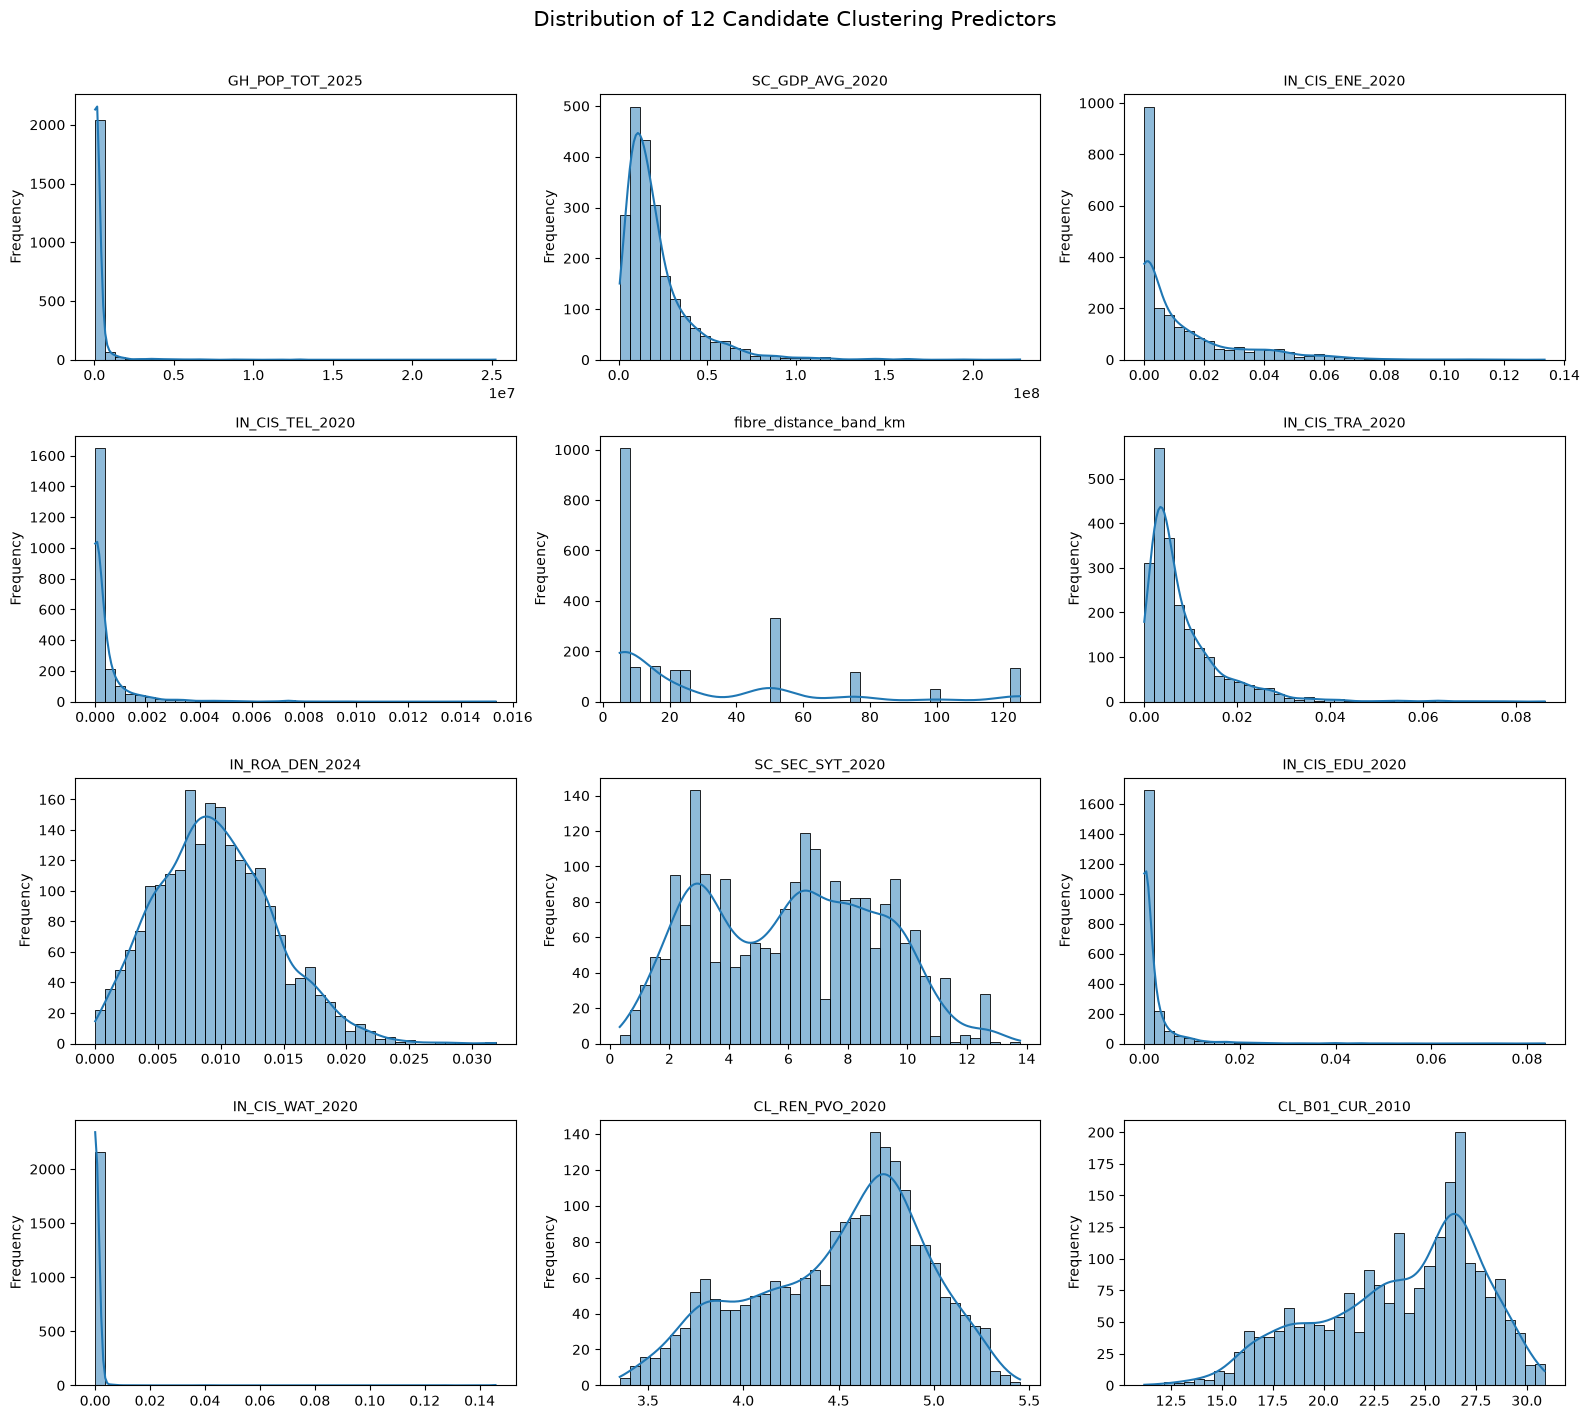

In [27]:

import matplotlib.pyplot as plt
import seaborn as sns

# Verify the clustering feature matrix
print("Shape:", X_candidate.shape)
print("All features numeric:", all(
    X_candidate.dtypes.apply(lambda dtype: pd.api.types.is_numeric_dtype(dtype))
))
print("Missing values:", X_candidate.isna().sum().sum())

# Visualize the distribution of all 12 predictors
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(X_candidate.columns):
    sns.histplot(
        X_candidate[col],
        bins=40,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frequency")

plt.suptitle(
    "Distribution of 12 Candidate Clustering Predictors",
    fontsize=15,
    y=1.01
)
plt.tight_layout()
plt.show()


### inspect the first five observations of our 12 clustering predictors.

In [28]:

# Display the first five urban centres and their 12 candidate predictors
display(X_candidate.head(5))


,GH_POP_TOT_2025,SC_GDP_AVG_2020,IN_CIS_ENE_2020,IN_CIS_TEL_2020,fibre_distance_band_km,IN_CIS_TRA_2020,IN_ROA_DEN_2024,SC_SEC_SYT_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010
0,8.827388e+04,24662104.38,2.620000e-08,2.460000e-07,15,0.002402,0.013276,6.713000,0.000719,6.260000e-09,4.327,23.108
1,3.970202e+06,62829932.16,2.131755e-02,1.385724e-03,10,0.038976,0.020983,5.047000,0.020982,1.617000e-04,4.747,24.496
2,1.313465e+06,13591185.78,4.863860e-04,1.402762e-03,5,0.012696,0.014302,5.764927,0.004661,5.970000e-05,4.672,25.180
3,1.774690e+05,28353481.96,1.800000e-05,5.439420e-04,5,0.006597,0.011540,9.137000,0.000048,3.690000e-06,5.101,20.147
4,6.744443e+05,18002209.03,0.000000e+00,2.830000e-06,5,0.006249,0.008329,6.934985,0.000695,0.000000e+00,4.519,26.630


In [29]:

# Display city and country alongside the 12 predictors
display(
    imputed_df[
        ["GC_UCN_MAI_2025", "GC_CNT_GAD_2025"]
        + X_candidate.columns.tolist()
    ].head(5)
)


,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GH_POP_TOT_2025,SC_GDP_AVG_2020,IN_CIS_ENE_2020,IN_CIS_TEL_2020,fibre_distance_band_km,IN_CIS_TRA_2020,IN_ROA_DEN_2024,SC_SEC_SYT_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010
0,Mindelo,Cabo Verde,8.827388e+04,24662104.38,2.620000e-08,2.460000e-07,15,0.002402,0.013276,6.713000,0.000719,6.260000e-09,4.327,23.108
1,Dakar,Senegal,3.970202e+06,62829932.16,2.131755e-02,1.385724e-03,10,0.038976,0.020983,5.047000,0.020982,1.617000e-04,4.747,24.496
2,Serrekunda,Gambia,1.313465e+06,13591185.78,4.863860e-04,1.402762e-03,5,0.012696,0.014302,5.764927,0.004661,5.970000e-05,4.672,25.180
3,Nouadhibou,Mauritania,1.774690e+05,28353481.96,1.800000e-05,5.439420e-04,5,0.006597,0.011540,9.137000,0.000048,3.690000e-06,5.101,20.147
4,Bissau,Guinea-Bissau,6.744443e+05,18002209.03,0.000000e+00,2.830000e-06,5,0.006249,0.008329,6.934985,0.000695,0.000000e+00,4.519,26.630


###  Quantify skewness

In [30]:

# Assess skewness across the 12 candidate predictors
skewness_summary = (
    X_candidate.skew()
    .sort_values(ascending=False)
    .to_frame(name="Skewness")
)

display(skewness_summary.round(3))


,Skewness
IN_CIS_WAT_2020,22.260
GH_POP_TOT_2025,13.113
IN_CIS_EDU_2020,6.765
IN_CIS_TEL_2020,5.454
IN_CIS_TRA_2020,3.017
SC_GDP_AVG_2020,3.000
IN_CIS_ENE_2020,1.953
fibre_distance_band_km,1.616
IN_ROA_DEN_2024,0.420
SC_SEC_SYT_2020,0.084


### Create our unified 13-variable matrix

In [31]:

# Create unified feature matrix, including PeeringDB
X_unified = imputed_df[
    X_candidate.columns.tolist() + ["peeringdb_facility_count"]
].copy()

print("Unified matrix shape:", X_unified.shape)
print("Missing values:", X_unified.isna().sum().sum())

# Display the first five observations with city and country
display(
    imputed_df[
        ["GC_UCN_MAI_2025", "GC_CNT_GAD_2025"]
        + X_unified.columns.tolist()
    ].head(5)
)


Unified matrix shape: (2172, 13)
Missing values: 0


,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GH_POP_TOT_2025,SC_GDP_AVG_2020,IN_CIS_ENE_2020,IN_CIS_TEL_2020,fibre_distance_band_km,IN_CIS_TRA_2020,IN_ROA_DEN_2024,SC_SEC_SYT_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010,peeringdb_facility_count
0,Mindelo,Cabo Verde,8.827388e+04,24662104.38,2.620000e-08,2.460000e-07,15,0.002402,0.013276,6.713000,0.000719,6.260000e-09,4.327,23.108,0
1,Dakar,Senegal,3.970202e+06,62829932.16,2.131755e-02,1.385724e-03,10,0.038976,0.020983,5.047000,0.020982,1.617000e-04,4.747,24.496,2
2,Serrekunda,Gambia,1.313465e+06,13591185.78,4.863860e-04,1.402762e-03,5,0.012696,0.014302,5.764927,0.004661,5.970000e-05,4.672,25.180,0
3,Nouadhibou,Mauritania,1.774690e+05,28353481.96,1.800000e-05,5.439420e-04,5,0.006597,0.011540,9.137000,0.000048,3.690000e-06,5.101,20.147,0
4,Bissau,Guinea-Bissau,6.744443e+05,18002209.03,0.000000e+00,2.830000e-06,5,0.006249,0.008329,6.934985,0.000695,0.000000e+00,4.519,26.630,0


### Visualize PeeringDB alongside the 12 predictors

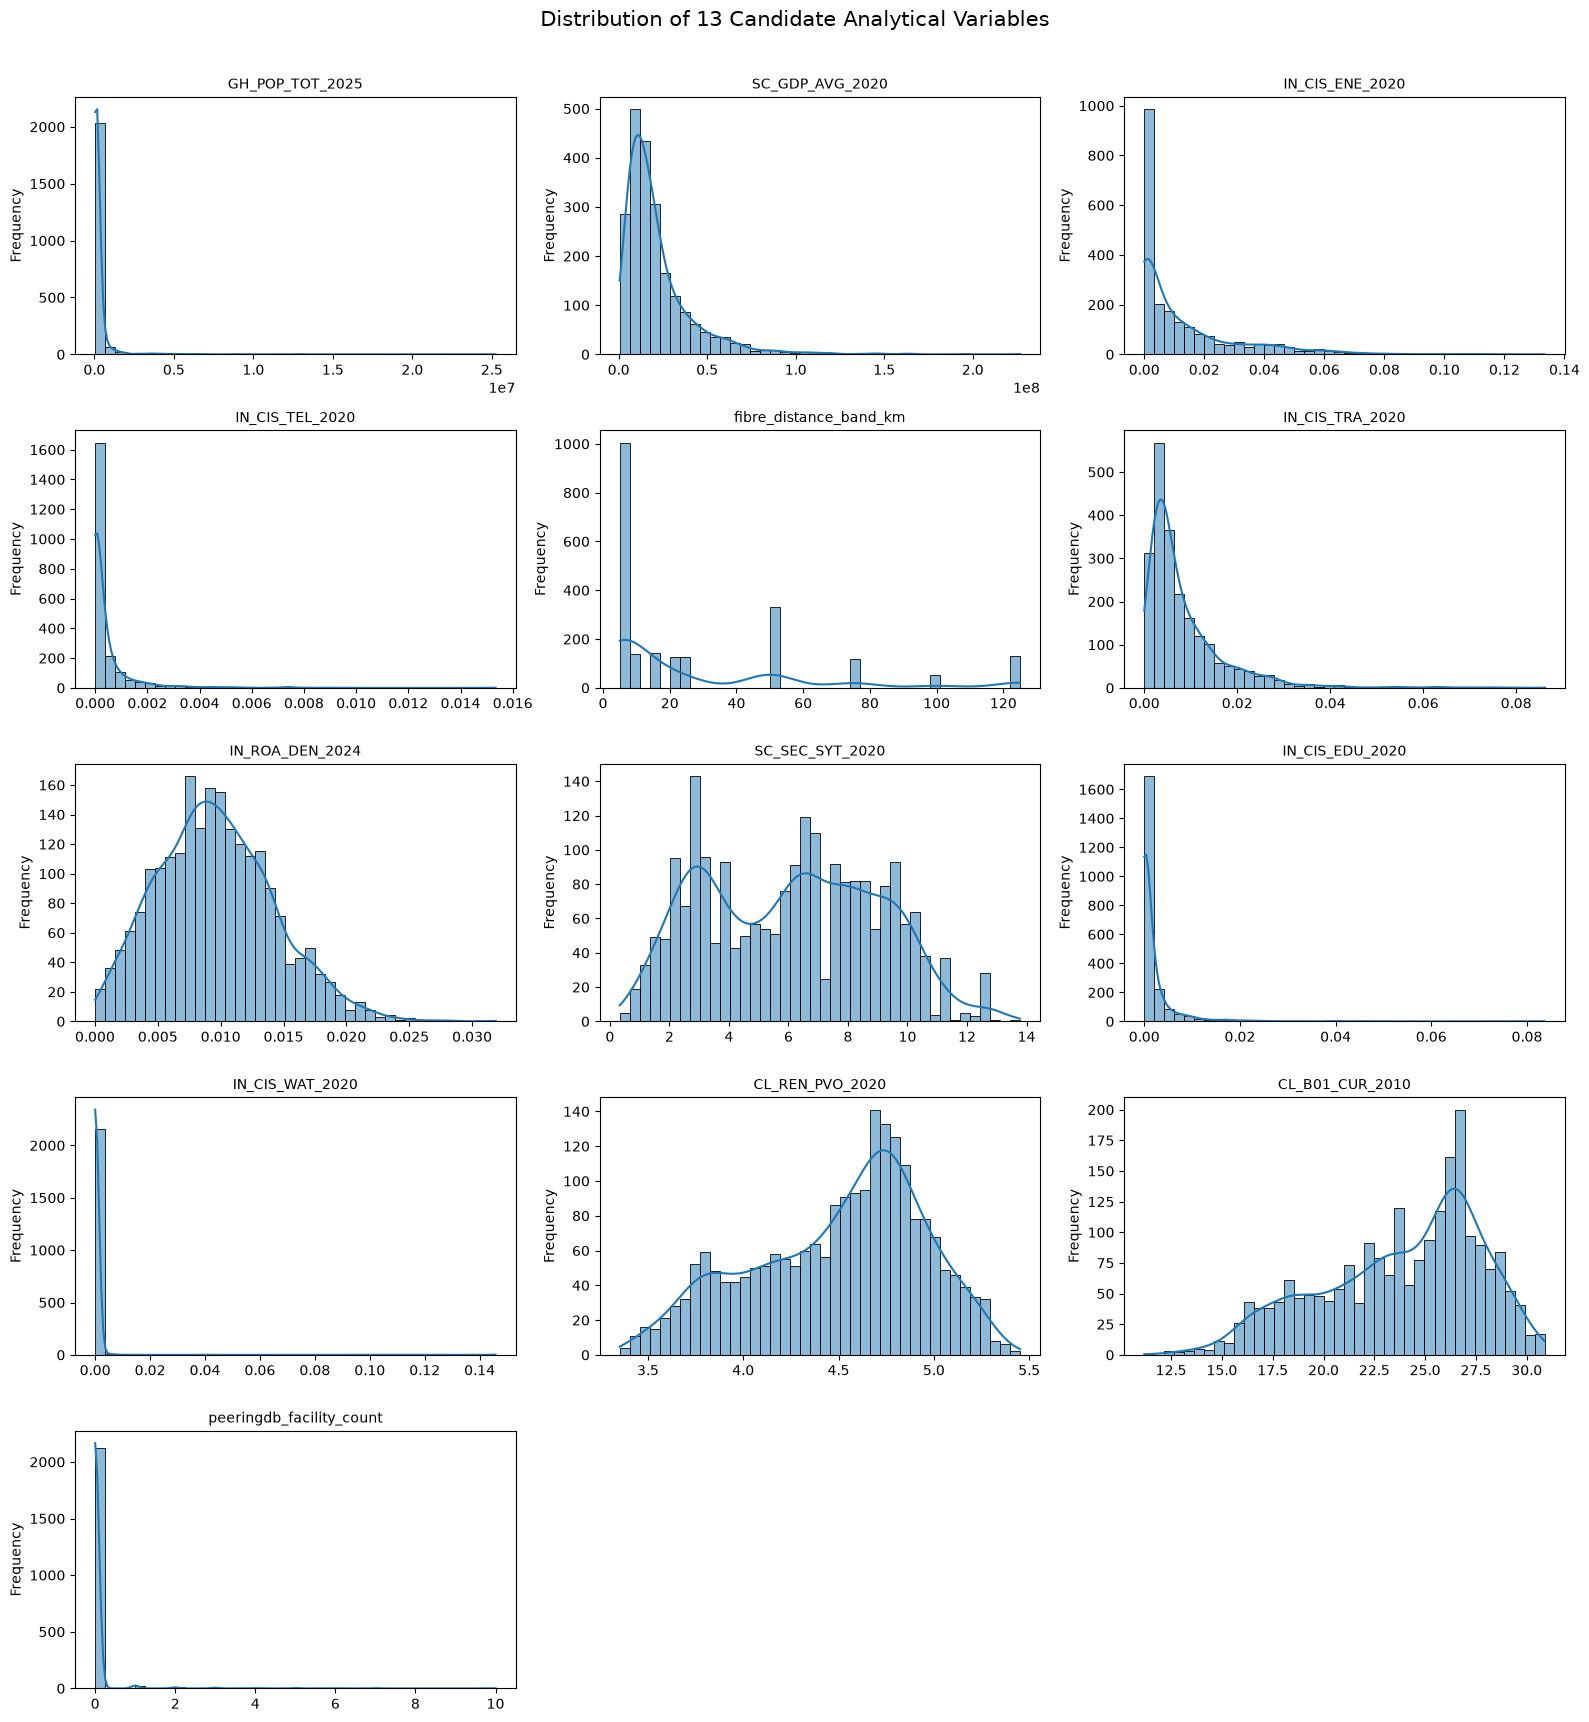

In [32]:

# Visualize all 13 numerical variables
fig, axes = plt.subplots(5, 3, figsize=(16, 17))
axes = axes.flatten()

for i, col in enumerate(X_unified.columns):
    sns.histplot(
        X_unified[col],
        bins=40,
        kde=True,
        ax=axes[i]
    )
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Frequency")

# Hide unused panels
for ax in axes[len(X_unified.columns):]:
    ax.set_visible(False)

plt.suptitle(
    "Distribution of 13 Candidate Analytical Variables",
    fontsize=15,
    y=1.01
)
plt.tight_layout()
plt.show()


### Quantify skewness across all 13 numerical variables

In [33]:

# Assess skewness across all 13 numerical variables
skewness_summary = (
    X_unified.skew()
    .sort_values(ascending=False)
    .to_frame(name="Skewness")
)

display(skewness_summary.round(3))


,Skewness
IN_CIS_WAT_2020,22.260
GH_POP_TOT_2025,13.113
peeringdb_facility_count,12.703
IN_CIS_EDU_2020,6.765
IN_CIS_TEL_2020,5.454
IN_CIS_TRA_2020,3.017
SC_GDP_AVG_2020,3.000
IN_CIS_ENE_2020,1.953
fibre_distance_band_km,1.616
IN_ROA_DEN_2024,0.420


### Examine ranges and zero concentrations

### Feature Distribution Assessment and Transformation Rationale

Visual inspection and skewness analysis of the 13 numerical variables revealed substantial differences in their distributions. Population (`GH_POP_TOT_2025`) and GDP (`SC_GDP_AVG_2020`) are strongly right-skewed, making them candidates for logarithmic transformation to reduce the influence of exceptionally large urban centres. The infrastructure indices, particularly water, education, telecommunications, transport and energy, also exhibit positive skewness; suitable transformations will be considered after examining their value ranges and zero concentrations. PeeringDB facility counts are highly right-skewed (12.703), reflecting the concentration of recorded facilities in a small number of urban centres. Given the sparse coverage of PeeringDB, this variable will be retained for comparative clustering experiments with and without its inclusion, rather than automatically transformed or included in the baseline model. The ITU fibre proximity variable is an ordinal representation of distance bands and will be assessed separately to preserve its interpretation. Road density, schooling, solar photovoltaic potential and temperature exhibit relatively low skewness and will initially be retained without transformation. These preliminary decisions aim to reduce the influence of extreme values while preserving meaningful variation in urban infrastructure, socioeconomic conditions and environmental characteristics. Final transformation and scaling choices will be informed by further distributional assessment and evaluated during clustering experiments.

In [34]:

# Examine ranges and zero concentrations
distribution_summary = X_unified.agg(
    ["min", "median", "max"]
).T

distribution_summary["Zero_Percent"] = (
    X_unified.eq(0).mean() * 100
)

distribution_summary["Skewness"] = X_unified.skew()

display(distribution_summary.round(4))


,min,median,max,Zero_Percent,Skewness
GH_POP_TOT_2025,50007.7464,1.011437e+05,2.523032e+07,0.0000,13.1127
SC_GDP_AVG_2020,575327.5833,1.552954e+07,2.267162e+08,0.0000,3.0003
IN_CIS_ENE_2020,0.0000,5.400000e-03,1.334000e-01,33.7937,1.9530
IN_CIS_TEL_2020,0.0000,0.000000e+00,1.530000e-02,54.0516,5.4542
fibre_distance_band_km,5.0000,1.000000e+01,1.250000e+02,0.0000,1.6162
IN_CIS_TRA_2020,0.0000,5.300000e-03,8.610000e-02,0.0460,3.0174
IN_ROA_DEN_2024,0.0000,9.300000e-03,3.190000e-02,0.0000,0.4201
SC_SEC_SYT_2020,0.3300,6.286000e+00,1.378200e+01,0.0000,0.0844
IN_CIS_EDU_2020,0.0000,1.000000e-04,8.370000e-02,40.4696,6.7646
IN_CIS_WAT_2020,0.0000,0.000000e+00,1.458000e-01,71.9153,22.2600


### Distributional Characteristics and Preliminary Preprocessing Decisions

Descriptive analysis of the 13 numerical variables revealed considerable differences in scale, skewness and zero concentration. Population and GDP exhibited substantial positive skewness and wide value ranges, supporting their consideration for logarithmic transformation. Several GHSL spatial infrastructure indices also showed positive skewness and substantial zero concentrations, particularly water (71.92%), telecommunications (54.05%), education (40.47%) and energy (33.79%). These characteristics warrant careful assessment of transformation methods, while recognizing that zero values in spatial indices should not automatically be interpreted as the absence of infrastructure services. The ITU fibre proximity variable will initially retain its encoded distance bands, while road density, schooling, solar photovoltaic potential and temperature will remain untransformed pending model evaluation. PeeringDB facility counts exhibited particularly high sparsity (97.79% zeros) and skewness (12.703), reinforcing the decision to compare baseline clustering without PeeringDB against an extended configuration incorporating this variable. The original analytical values will be preserved, with transformations and scaling applied separately during model experimentation to ensure reproducibility and enable comparison of alternative preprocessing strategies.

### Export the unified dataset

In [35]:

from pathlib import Path

# Define output directory
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

# Preserve city identifiers alongside the 13 numerical variables
analytical_df = imputed_df[
    ["ID_UC_G0", "GC_UCN_MAI_2025", "GC_CNT_GAD_2025"]
    + X_unified.columns.tolist()
].copy()

# Validate before saving
assert analytical_df.shape == (2172, 16)
assert analytical_df["ID_UC_G0"].is_unique
assert analytical_df[X_unified.columns].notna().all().all()

# Save the prepared dataset
output_path = output_dir / "africa_ai_readiness_analytical.csv"
analytical_df.to_csv(output_path, index=False)

print("Saved to:", output_path.resolve())
print("Dataset shape:", analytical_df.shape)
print("Numerical predictors:", len(X_unified.columns))


Saved to: D:\Purity\GitHub-Repository\africa-ai-readiness-investment-intelligence\data\processed\africa_ai_readiness_analytical.csv
Dataset shape: (2172, 16)
Numerical predictors: 13


### Verify the saved file

In [36]:

# Reload and verify the exported dataset
saved_df = pd.read_csv(output_path)

print("Reloaded shape:", saved_df.shape)
print("Missing predictor values:",
      saved_df[X_unified.columns].isna().sum().sum())

display(saved_df.head())


Reloaded shape: (2172, 16)
Missing predictor values: 0


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GH_POP_TOT_2025,SC_GDP_AVG_2020,IN_CIS_ENE_2020,IN_CIS_TEL_2020,fibre_distance_band_km,IN_CIS_TRA_2020,IN_ROA_DEN_2024,SC_SEC_SYT_2020,IN_CIS_EDU_2020,IN_CIS_WAT_2020,CL_REN_PVO_2020,CL_B01_CUR_2010,peeringdb_facility_count
0,38,Mindelo,Cabo Verde,8.827388e+04,24662104.38,2.620000e-08,2.460000e-07,15,0.002402,0.013276,6.713000,0.000719,6.260000e-09,4.327,23.108,0
1,39,Dakar,Senegal,3.970202e+06,62829932.16,2.131755e-02,1.385724e-03,10,0.038976,0.020983,5.047000,0.020982,1.617000e-04,4.747,24.496,2
2,40,Serrekunda,Gambia,1.313465e+06,13591185.78,4.863860e-04,1.402762e-03,5,0.012696,0.014302,5.764927,0.004661,5.970000e-05,4.672,25.180,0
3,41,Nouadhibou,Mauritania,1.774690e+05,28353481.96,1.800000e-05,5.439420e-04,5,0.006597,0.011540,9.137000,0.000048,3.690000e-06,5.101,20.147,0
4,43,Bissau,Guinea-Bissau,6.744443e+05,18002209.03,0.000000e+00,2.830000e-06,5,0.006249,0.008329,6.934985,0.000695,0.000000e+00,4.519,26.630,0


### Final Analytical Dataset — Export

Following data integration, validation, missing-value imputation and distributional assessment, a unified analytical dataset was prepared for clustering experiments. The exported dataset contains 2,172 African urban centres, 13 numerical variables (11 GHSL indicators, one ITU fibre proximity indicator and one PeeringDB facility-count indicator), and three identification fields. All numerical variables are complete following imputation. Original values have been preserved without transformation or scaling. The dataset will support two clustering configurations: a 12-feature baseline excluding PeeringDB and a 13-feature extended configuration including PeeringDB. Alternative transformations, scaling approaches and clustering algorithms will be evaluated in Notebook 02.